# Emg3d pyGIMLI inversion testing

Requires
- `pygimli>=1.5.2`
- ipygimli.py

v1: try to invert for a cuboid hot plume, with minimal noise, inverting only for the value of the anomaly resistivity and taking the background as (correctly) known

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

import emg3d
import ipygimli as ipygimli
from Emg3d_extra_grid_functions import *
import h5py

In [2]:
#Random number regenerator used to set the noise, seed guarantees the same noise is reproduced each time, can be adapted with different numbers to test different noise
rng_real = np.random.default_rng(seed=0)
rng_imag = np.random.default_rng(seed=1)

## Create synthetic data

Model used in previous forward-modeling (v1), with a cuboid hot plume inside

### Define survey and baseline resistivity model

In [3]:
# Source, y-directed point dipole on the surface
src_coords = (0, -126, 0, 90.0, 0.0)
src = emg3d.surveys.txrx_coordinates_to_dict(emg3d.TxElectricDipole, src_coords)

# Source frequency
frequency = 1

# Receivers, vertical z-directed point dipoles
rec_x = np.arange(1, 41)*0
rec_y = np.array([74]*40)
rec_z = np.arange(1,41)*-7.5
rec_coords = (rec_x, rec_y, rec_z, 0.0, 90.0)
rec = emg3d.surveys.txrx_coordinates_to_dict(emg3d.RxElectricPoint, rec_coords)

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)

In [4]:
# define the input that stays the same for all models
inp = {
    'src': src,
    'rec': rec,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

In [5]:
grid = emg3d.construct_mesh(
    center=(0,0,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-100, 100], [-300, 0]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [25, 25, 5],
)
 
grid  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 294,912 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     48   -105,390.51    105,390.51     25.00 31,649.36    1.43
   y     48   -105,390.51    105,390.51     25.00 31,649.36    1.43
   z    128   -106,386.28    137,173.52      5.00 31,082.24    1.29

In [6]:
#Insert resistivity values into the grid

# Pre-allocate an array with number of cells corresponding to our grid
res_base = np.ones(grid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    res_base[:, :, (grid.cell_centers_z > dd[i+1]) & (grid.cell_centers_z <= dd[i])] = resistivities_base[i]

model_base = emg3d.Model(grid, property_x=res_base, mapping='Resistivity')
model_base_conductivity = emg3d.Model(grid, property_x=1/np.array(res_base), mapping='Conductivity')

### Create target model

In [7]:
#Use predefined function to insert a cuboid inton the target layer

x_extent = 50
y_extent = 50
zmin = depth[4]
zmax = depth[3]
res_target = 1 # emphasizing the contrast to make inversion easier

res_target2 = change_cuboid_resistivity(res_base.copy(), grid, x_extent, y_extent, zmin, zmax, res_target)

model_target2 = emg3d.Model(grid, property_x=res_target2, mapping='Resistivity')
model_target2_conductivity = emg3d.Model(grid, property_x=1/np.array(res_target2), mapping='Conductivity')

[-50, -50, -190] [50, 50, -120]
x bounds:  -37.50000000000071  ,  37.49999999999929
y_bounds:  -37.50000000000071  ,  37.49999999999929
z_bounds:  -187.49999999998926  ,  -122.49999999998926


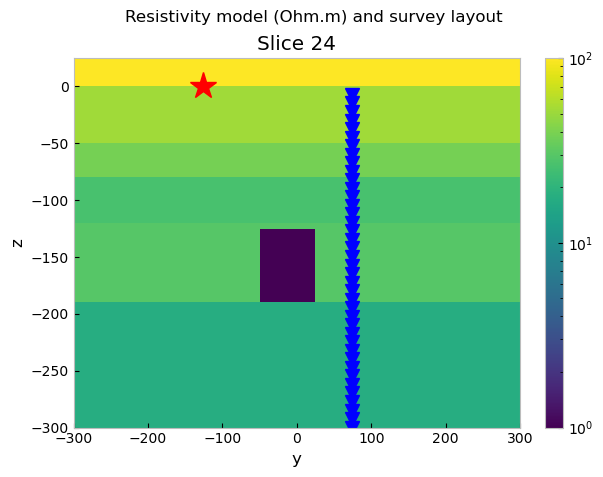

In [8]:
#Focus on the y,z plane
f0 = grid.plot_slice(
    model_target2.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(src_coords[1], src_coords[2], 'r*', markersize = 20)
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

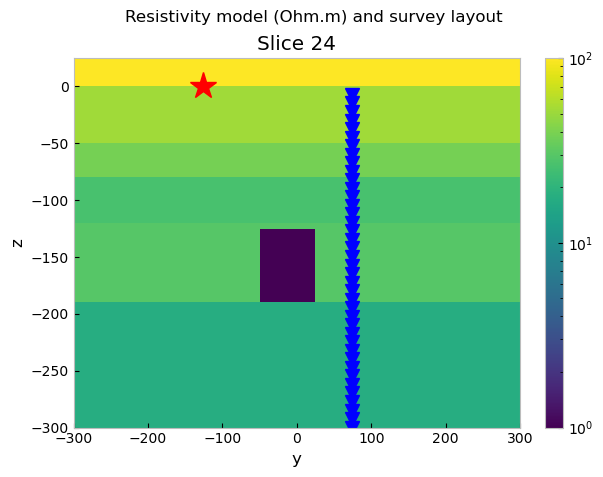

In [9]:
#Focus on the y,z plane
f0 = grid.plot_slice(
    1/model_target2_conductivity.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(src_coords[1], src_coords[2], 'r*', markersize = 20)
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

### Create the simulated data

Code is based on sensitivity gradient notebook v1_7

We want to create a simulation class with the true model data + noise as observed data and the starting model as the model

In [10]:
# Parameterize the noise to be added

noise_floor = 1e-15
relative_error = 0.01
mean_noise = 0.0

In [11]:
#Generate frequency- and source-dependent grids
gopts = {
    'properties': [25, 1e8],
    'min_width_limits': [25, 25, 5],
    #'stretching': (None, None, [1.0, 1.5]),
    'domain': (
        [-100, 100],
        [-100, 100],
        [-300, 0]
    ),
    'center_on_edge': False,
}

In [12]:
survey = emg3d.surveys.Survey(
    name='Survey cuboid target model',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    # data=data,               # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)

In [13]:
# simulate with the true model to create the observed data

simulation = emg3d.simulations.Simulation(
            name='Simulation of cuboid target model',    # A name for this simulation
            survey=survey,        # Our survey instance
            model=model_target2_conductivity,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear" #Needed for correct computation of the gradient
        )

simulation.compute(observed=True)
#The simulation should now contain observed data (+noise), synthetic data (without noise) and standard deviation values
#The survey class is also updated with this information

Compute efields            0/1  [00:00]

In [14]:
# Check observed values with default noise computation
print(np.array(survey.data['observed']).flatten()[10])
print(np.array(survey.data['observed']).flatten()[20])

(-5.280217341319031e-07+9.255582906866217e-10j)
(-3.6543426919658606e-07+1.0531073558226737e-09j)


In [15]:
# Re-compute the noise and overwrite the data, based on empymod+pygimli testing

dobs = survey.data['synthetic']

# Add random white noise to dobs
std_dev_real = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.real)**2)
std_dev_imag = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.imag)**2)
noise_real = rng_real.normal(loc=0, scale=std_dev_real, size = dobs.shape)
noise_imag = rng_imag.normal(loc=0, scale=std_dev_imag, size = dobs.shape)
std_dev = std_dev_real + 1j*std_dev_imag
noise = noise_real + 1j*noise_imag
dobs += noise
dobs0 = dobs
noise0 = noise

# Overwrite values in survey
survey.data['observed'] = dobs
survey.standard_deviation = std_dev

In [16]:
survey2 = emg3d.surveys.Survey(
    name='Survey to go into inversion',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    data=survey.data['observed'], # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)
survey2.standard_deviation = survey.standard_deviation

In [17]:
# Check observed values with new noise computation
print(np.array(survey2.data['observed']).flatten()[10])
print(np.array(survey2.data['observed']).flatten()[20])

(-5.313127587573941e-07+9.258213550990544e-10j)
(-3.659039789027799e-07+1.0531931017250232e-09j)


In [18]:
simulation2 = emg3d.simulations.Simulation(
            name='Simulation to go into inversion 2',    # A name for this simulation
            survey=survey2,        # Our survey instance
            model=model_base_conductivity,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear", #Needed for correct computation of the gradient
            tqdm_opts = False #To switch-off progress bar during inversion
        )

simulation2.compute(observed=False)

#We don't lput observed=True in this case because this will overwrite the observed data saved inside the survey

In [19]:
# Check that observed data values are not overwritten
print(np.array(survey2.data['observed']).flatten()[10])
print(np.array(survey2.data['observed']).flatten()[20])

(-5.313127587573941e-07+9.258213550990544e-10j)
(-3.659039789027799e-07+1.0531931017250232e-09j)


In [20]:
from matplotlib.ticker import StrMethodFormatter, NullFormatter


(179.5, 180.0)

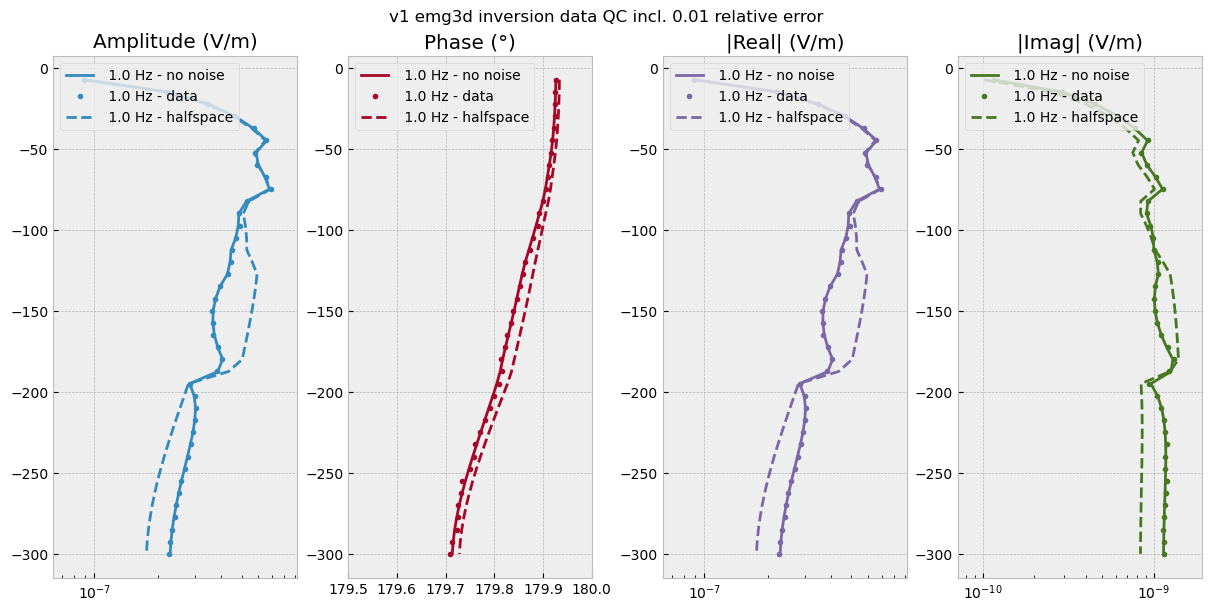

In [21]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]
dhalf = np.array(survey2.data['synthetic'])[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_half = [np.abs(dhalf), np.angle(dhalf,deg=True), abs(dhalf.real), abs(dhalf.imag)]
fig.suptitle("v1 emg3d inversion data QC incl. "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_half[j][:], rec_coords[2], 'C'+str(j)+'--', label=f"{frequency: 2.1f} Hz - halfspace")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

Note that the forward-modelling gave a result like this before:

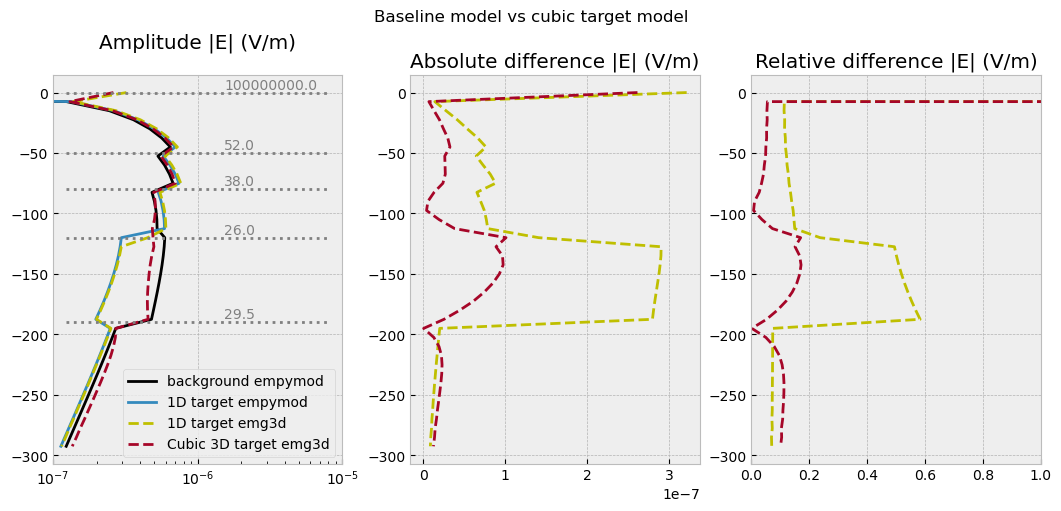

## Define regions, instantiate Kernel and Inversion

We only invert for the value of the anomaly, not the location, by marking the region of the anomaly and using single=True in pyGIMLi's region manager

In [22]:
# Create region markers
markers = np.zeros(simulation2.model.shape, dtype=int)
markers[model_target2.property_x < 15] = 1            # Only target is free

# Instantiate the emg3d-kernel for pyGIMLi
fop = ipygimli.Kernel(simulation=simulation2, markers=markers, pgthreads=1)

# Instantiate the inversion and set some inversion parameters
INV = ipygimli.Inversion(fop=fop)
#INV.inv.setCGLSTolerance(1)  # is _absolute_, not _relative_
INV.inv.setMaxCGLSIter(10)

# Set the regions.
INV.fop.setRegionProperties(1, single=True, limits=(0.01, 2)) # Target
INV.fop.setRegionProperties(0, background=True) # Background

In [25]:
print(np.shape(simulation2.model))
print(np.shape(simulation2.model.property_x))

(48, 48, 128)
(48, 48, 128)


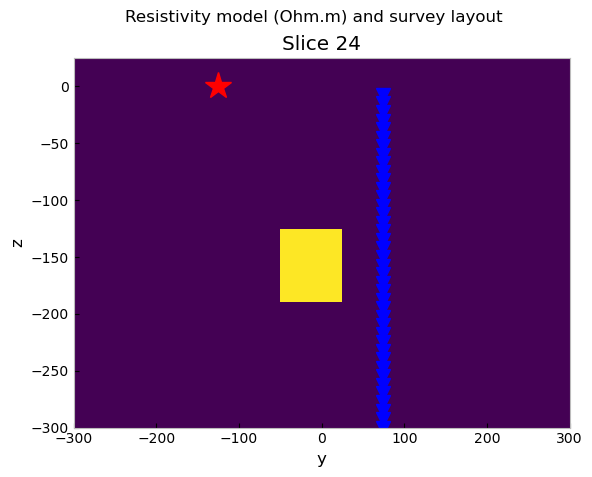

In [26]:
# QC the inversion region corresponds to the wanted region
# #Focus on the y,z plane
grid.plot_slice(
    markers,
    normal = 'X',
    #pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(src_coords[1], src_coords[2], 'r*', markersize = 20)
axs[1].grid(False)

## Run inversion

In [27]:
INV.run(
    #maxIter=2, # just to test
    lam=20,  # btw 1-100
    lambdaFactor=10,
    stopAtChi1=False,
    dPhi=1.0,
    #verbose=True,
    #debug=True,
    #startModel=model.property_x.ravel('F'),
    #isReference=True, 
)

24/08/26 - 20:08:47 - pyGIMLi - INFO - :: pyGIMLi(emg3d) START ::
24/08/26 - 20:08:56 - pyGIMLi - INFO - ===========================================================================
                                        it   F(m)         χ²          λ         ϕᵈ         ϕᵐ   ϕ=ϕᵈ+λϕᵐ   Δϕ (%)
                                       ---------------------------------------------------------------------------
24/08/26 - 20:08:56 - pyGIMLi - INFO -   0      1      491.4       20.0    39311.6       19.4    39700.6     0.00
24/08/26 - 20:09:19 - pyGIMLi - INFO -   1     24      430.4       20.0    34434.8       16.5    34765.3    12.43
24/08/26 - 20:09:42 - pyGIMLi - INFO -   2     24      215.7      200.0    17253.5        8.5    18950.7    45.49
24/08/26 - 20:10:05 - pyGIMLi - INFO -   3     24       21.8     2000.0     1743.4        1.4     4463.2    76.45
24/08/26 - 20:10:27 - pyGIMLi - INFO -   4     24        0.8    20000.0       61.3        0.0      102.8    97.70
24/08/26 - 20:10:41 

# Plots

In [29]:
# Load relevant inversion parameters saved through post_step (ipygimli functionality)

inv_data = h5py.File("Simulation to go into inversion 2.h5",'r')

phi_history = []
for i in np.arange(len(INV.modelHistory)):
    phi_history.append(int(np.array(inv_data['invinfo'][str(i)]['phi'])))

print(phi_history)

[39700, 34765, 18950, 4463, 102, 59, 59]


Text(0.5, 1.0, 'Inversion information')

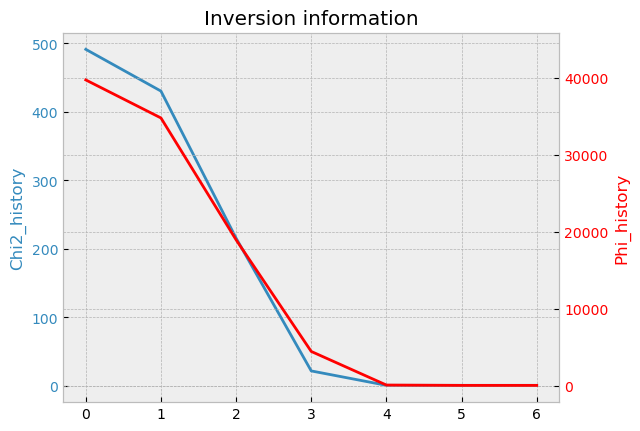

In [30]:
fig, ax = plt.subplots()

ax.plot(INV.chi2History)
ax.tick_params(axis='y', labelcolor='C0')
ax.set_ylabel('Chi2_history', color = 'C0')
ax2 = ax.twinx()
ax2.plot(phi_history, c = 'red')
ymin, ymax = ax2.get_ylim()
ax2.set_ylim([ymin*1.1, ymax*1.1])
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylabel('Phi_history', c='red')
ax.set_title('Inversion information')

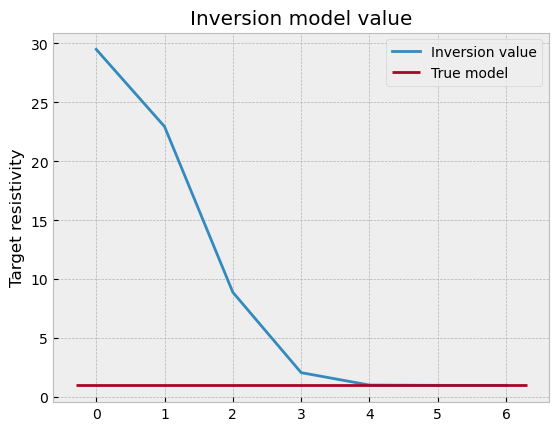

In [31]:
fig, ax = plt.subplots()

ax.plot(1/np.array(INV.modelHistory), label='Inversion value')
ax.set_ylabel('Target resistivity')
ax.set_title('Inversion model value')
xmin, xmax = ax.get_xlim()
ax.hlines(y = res_target, xmin=xmin, xmax=xmax, color='C1', label= 'True model')
ax.legend()

Text(0.5, 0.98, 'Resistivity models (Ohmm) per iteration')

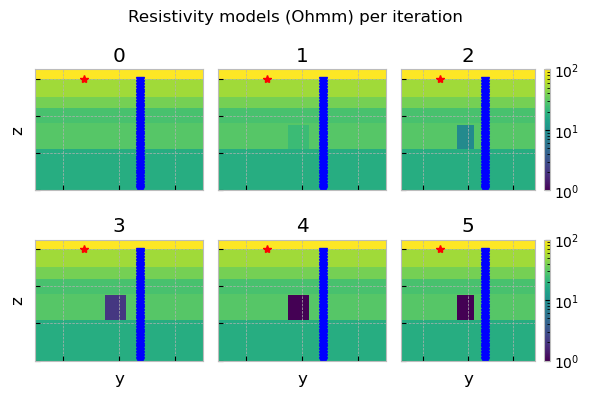

In [32]:
#Code adapted from plot_models function in sampledata.py

sim_amount = len(INV.chi2History)
n_rows = 2
n_columns = 3
depth = 150
vmin = 1e0
vmax = 100

popts = {'cmap': 'viridis', 'norm': LogNorm(vmin=vmin, vmax=vmax)} #Normalize(vmin=vmin, vmax=vmax)}
# popts2 = {'edgecolors': 'grey', 'linewidth': 0.5, 'cmap': 'Spectral_r',
#           'norm': LogNorm(vmin=0.1, vmax=1000)}
opts = {'v_type': 'CC', 'normal': 'X', 'range_x': [-300, 300], 'range_y': [-300, 25],}

fig, axs = plt.subplots(n_rows, n_columns, figsize=(n_columns*2, n_rows*2), tight_layout=True, sharex = True, sharey = True)

for i in np.arange(sim_amount-1):
    ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
    m_it = 1/fop.model2emg3d(INV.modelHistory[i])

    # Plotting the model
    out = grid.plot_slice(m_it, ax=ax, pcolor_opts=popts, **opts)
    ax.set_title(str(i))
    ax.plot(rec_coords[1], rec_coords[2], 'bv')
    ax.plot(src_coords[1], src_coords[2], 'r*')
    if i%n_columns != 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])
        if i%n_columns == n_rows:
            plt.colorbar(out[0], ax=ax)#, fraction=.5, shrink=.8, aspect=30)
    
for i in np.arange(sim_amount-1-n_columns):
        ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
        ax.set_xlabel('')
        ax.set_xticklabels([])

    #for ax in axs.ravel():
    #    ax.axis('equal')
fig.suptitle('Resistivity models (Ohmm) per iteration')



(179.5, 180.0)

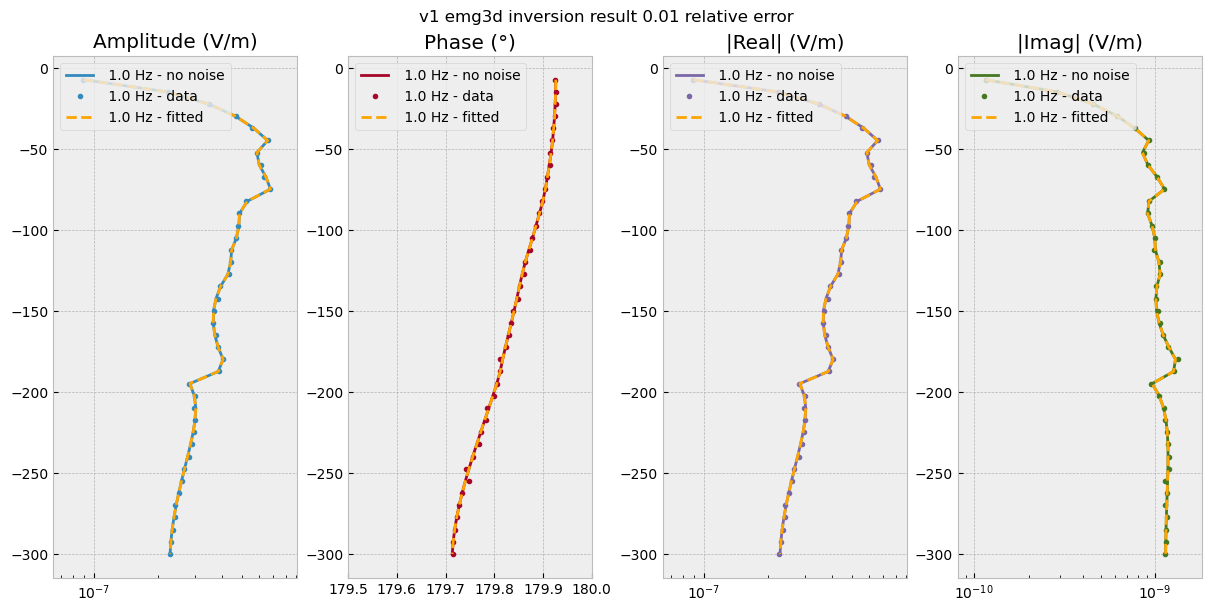

In [ ]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]
response = simulation2.survey.data.synthetic[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
fig.suptitle("v1 emg3d inversion result "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - fitted")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

(179.5, 180.0)

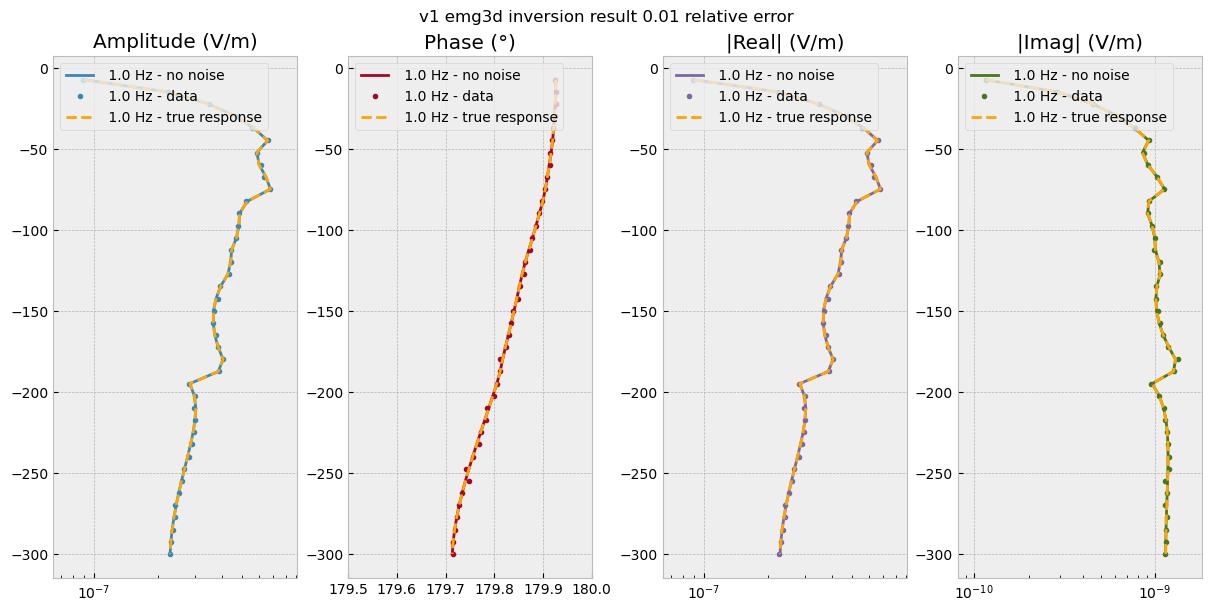

In [ ]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]

response = fop.data2emg3d(fop.response(fop.model2gimli(model_target2_conductivity.property_x)))[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
fig.suptitle("v1 emg3d inversion result "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - true response")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

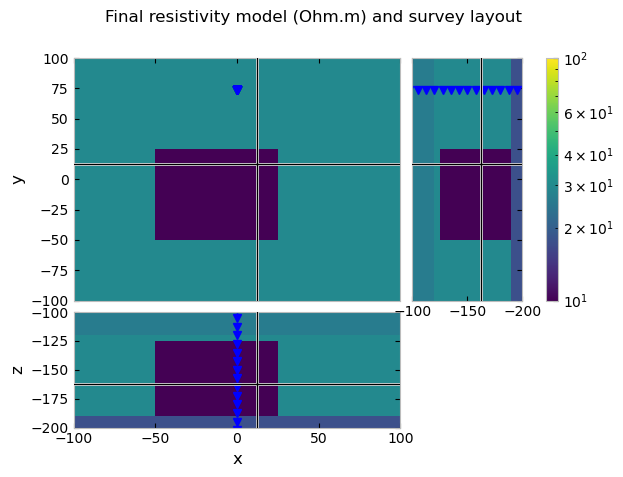

In [ ]:
#QC cube location
grid.plot_3d_slicer(
    1/fop.model2emg3d(INV.modelHistory[-1]),
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -100],
    zslice=-160,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Final resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[0], rec_coords[1], 'bv')
axs[2].plot(rec_coords[0], rec_coords[2], 'bv')
axs[3].plot(rec_coords[2], rec_coords[1], 'bv')
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

In [32]:
#Custom plume model

model1 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)
model2 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)
model3 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)

manual_plot_slice_3x(model1, model2, model3, y_extent=-100, zmin=-200, zmax=-100, size_y = 6.4, size_z = 4.8, vmin = 1e1, vmax = 1e2)

RuntimeError: ./core/src/matrix.h:466		GIMLI::Vector<ValueType2>& GIMLI::Matrix<ValueType>::rowRef(GIMLI::Index) [with ValueType = double; GIMLI::Index = long long unsigned int]  80 <= 80

In [33]:
A = INV.fop.jacobian()
jacobians = pg.sparseMatrix2Array(A)
#print(A)
#A*np.arange(1
#print(np.shape(np.sum(INV.fop.jacobian(), axis=0)))

NameError: name 'pg' is not defined

In [26]:
def crop_model(model3D, grid, x_slice = 0, y_extent=300, zmin=-250, zmax=0):

    #This method assumes cell_centers are the relevant parameters
    ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(grid, x_slice, y_extent, zmin, zmax, QC=True)

    #QC the bounds
    print('x position: ', grid.cell_centers_x[ix_max])
    print('y_bounds: ', grid.cell_centers_y[iy_min], ' , ', grid.cell_centers_y[iy_max])
    print('z_bounds: ', grid.cell_centers_z[iz_min], ' , ', grid.cell_centers_z[iz_max])

    # Crop Ez field array
    crop_model3D = model3D[ix_max, iy_min:iy_max, iz_min:iz_max]
    crop_model3D = np.flip(np.transpose(crop_model3D), axis=0)

    return crop_model3D

In [26]:
from sampledata import *

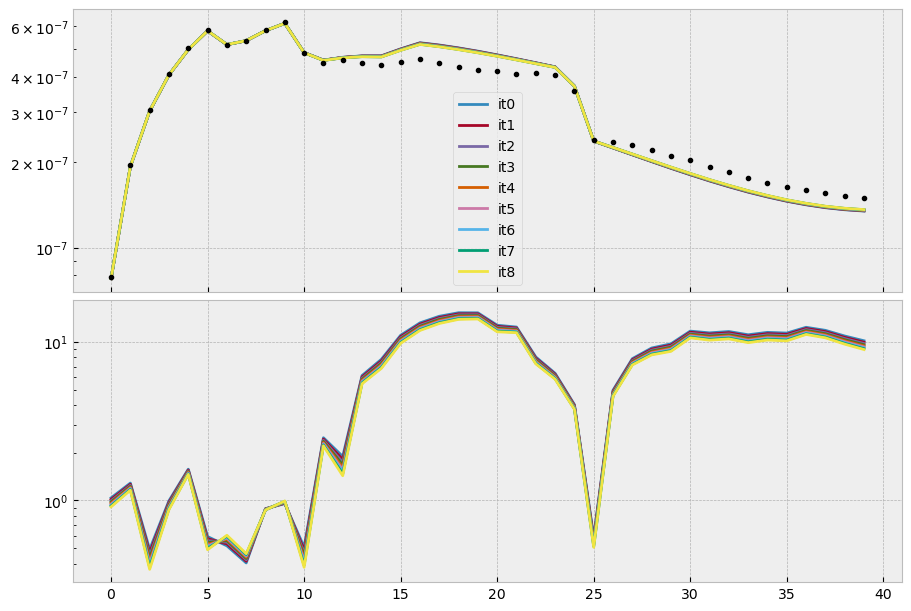

In [28]:
plot_responses(simulation2)

In [8]:
emg3d.Report()

--------------------------------------------------------------------------------
  Date: Tue Sep 10 17:08:40 2024 CEST

                OS : Linux (Ubuntu 22.04)
            CPU(s) : 16
           Machine : x86_64
      Architecture : 64bit
               RAM : 31.0 GiB
       Environment : Jupyter
       File system : ext4

  Python 3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:36:13) [GCC
  12.3.0]

             numpy : 1.26.4
             scipy : 1.14.0
             numba : 0.59.1
             emg3d : 1.8.4.dev6+gd2f88de
           empymod : 2.3.1
            xarray : 2024.6.0
        discretize : 0.10.0
              h5py : 3.11.0
        matplotlib : 3.9.1
              tqdm : 4.66.4
           IPython : 8.26.0
           pygimli : 1.5.2
            pgcore : 1.5.0
--------------------------------------------------------------------------------